In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PATH = Path(r"D:\FINAL DFDT\SELECTED_DATASET")
SPLIT_PATH = DATASET_PATH / "splits"

split_manifest = pd.read_csv(
    SPLIT_PATH / "dataset_split_manifest.csv"
)

print("Total images:", len(split_manifest))
print(split_manifest["split"].value_counts())

Total images: 10000
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64


In [2]:
split_manifest["image_path"] = split_manifest.apply(
    lambda row: str(
        DATASET_PATH /
        row["class"].lower() /
        Path(row["destination_image"]).name
    ),
    axis=1
)

split_manifest["label"] = (
    split_manifest["class"].map({"REAL": 0, "FAKE": 1})
)

missing = [
    p for p in split_manifest["image_path"]
    if not Path(p).exists()
]

print("Missing images:", len(missing))

assert len(missing) == 0
assert split_manifest["label"].notna().all()

Missing images: 0


In [3]:
dimension_records = []

for image_path in split_manifest["image_path"]:
    with Image.open(image_path) as img:
        dimension_records.append({
            "width": img.width,
            "height": img.height,
            "mode": img.mode
        })

dimension_df = pd.DataFrame(dimension_records)

print("Image dimensions:")
display(dimension_df.value_counts().reset_index(name="count"))

print("\nColor modes:")
print(dimension_df["mode"].value_counts())

Image dimensions:


,width,height,mode,count
0,256,256,RGB,10000



Color modes:
mode
RGB    10000
Name: count, dtype: int64


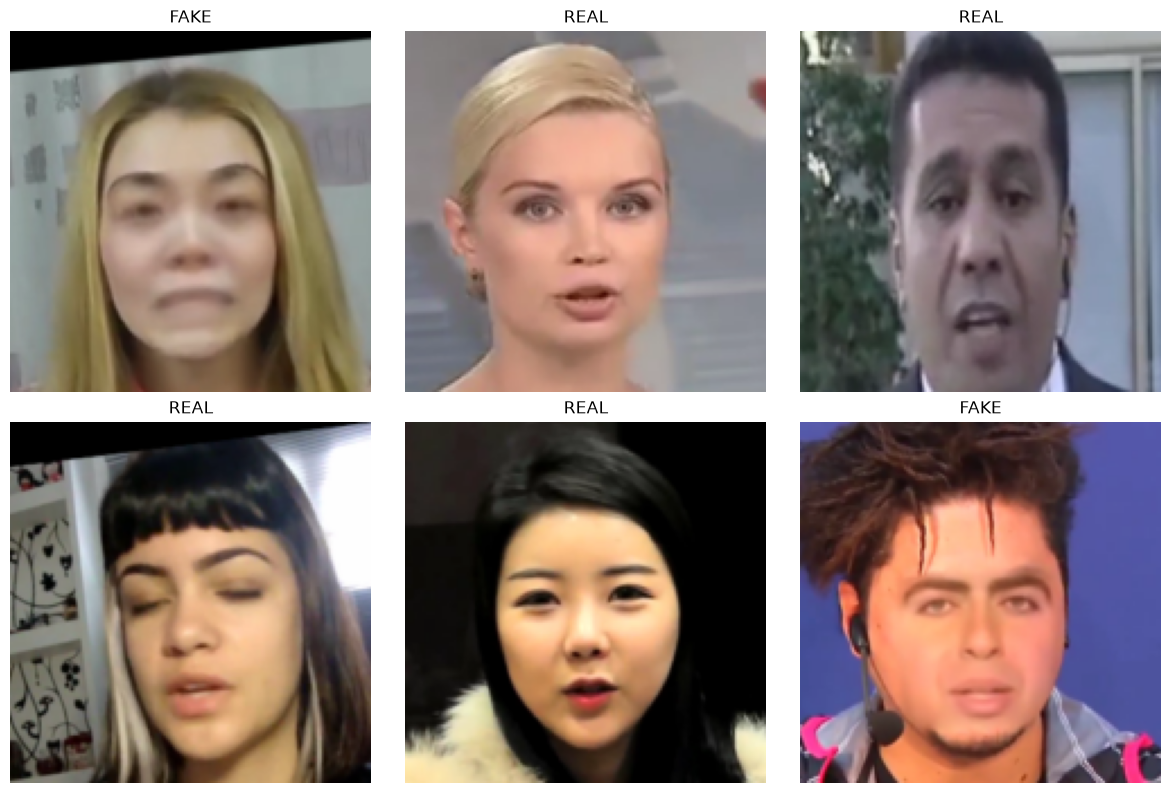

Preprocessing sample test completed.
Input shape: (160, 160, 3)
Normalized range: -1.9831933 2.2489083


In [4]:
IMG_SIZE = 160

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image, dtype=np.float32
    ) / 255.0

    normalized = (
        image_array - IMAGENET_MEAN
    ) / IMAGENET_STD

    return image_array, normalized

sample = split_manifest.sample(
    n=6, random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image, normalized = preprocess_image(row["image_path"])

    ax.imshow(image)
    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Preprocessing sample test completed.")
print("Input shape:", normalized.shape)
print("Normalized range:", normalized.min(), normalized.max())

In [5]:
# Final preprocessing validation

sample_path = split_manifest.iloc[0]["image_path"]

raw_image, normalized_image = preprocess_image(sample_path)

print("Raw image shape:", raw_image.shape)
print("Normalized shape:", normalized_image.shape)

print("\nRaw pixel range:")
print("Minimum:", raw_image.min())
print("Maximum:", raw_image.max())

print("\nNormalized pixel range:")
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())

print("\nNaN values:", np.isnan(normalized_image).sum())
print("Infinite values:", np.isinf(normalized_image).sum())

assert raw_image.shape == (160, 160, 3)
assert normalized_image.shape == (160, 160, 3)
assert np.isfinite(normalized_image).all()

print("\nPREPROCESSING VALIDATION PASSED!")

Raw image shape: (160, 160, 3)
Normalized shape: (160, 160, 3)

Raw pixel range:
Minimum: 0.03529412
Maximum: 1.0

Normalized pixel range:
Minimum: -1.8610327
Maximum: 2.64

NaN values: 0
Infinite values: 0

PREPROCESSING VALIDATION PASSED!
